In [155]:
# BƯỚC 1: Import thư viện
import pandas as pd
import numpy as np

# BƯỚC 2: Đọc dữ liệu BankSim
df = pd.read_csv(
    "../data/raw/bs140513_032310.csv",
    sep=",",
    quotechar="'"
)

# BƯỚC 3: Hiển thị 5 dòng đầu tiên
df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,C1093826151,4,M,28007,M348934600,28007,es_transportation,4.55,0
1,0,C352968107,2,M,28007,M348934600,28007,es_transportation,39.68,0
2,0,C2054744914,4,F,28007,M1823072687,28007,es_transportation,26.89,0
3,0,C1760612790,3,M,28007,M348934600,28007,es_transportation,17.25,0
4,0,C757503768,5,M,28007,M348934600,28007,es_transportation,35.72,0


In [156]:
# Kiểm tra kích thước dữ liệu
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

# Kiểm tra tên các cột
print("Danh sách cột:")
print(df.columns.tolist())

Số dòng: 594643
Số cột: 10
Danh sách cột:
['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant', 'zipMerchant', 'category', 'amount', 'fraud']


In [157]:
# Kiểm tra thông tin tổng quan của dữ liệu
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  str    
 2   age          594643 non-null  str    
 3   gender       594643 non-null  str    
 4   zipcodeOri   594643 non-null  int64  
 5   merchant     594643 non-null  str    
 6   zipMerchant  594643 non-null  int64  
 7   category     594643 non-null  str    
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(4), str(5)
memory usage: 67.6 MB


In [158]:
# Đếm số lượng dữ liệu thiếu ở từng cột
missing_data = df.isnull().sum()

print("Số lượng dữ liệu thiếu:")
print(missing_data)

# Tính tỷ lệ dữ liệu thiếu
missing_percent = (df.isnull().sum() / len(df)) * 100

print("\nTỷ lệ dữ liệu thiếu (%):")
print(missing_percent)

Số lượng dữ liệu thiếu:
step           0
customer       0
age            0
gender         0
zipcodeOri     0
merchant       0
zipMerchant    0
category       0
amount         0
fraud          0
dtype: int64

Tỷ lệ dữ liệu thiếu (%):
step           0.0
customer       0.0
age            0.0
gender         0.0
zipcodeOri     0.0
merchant       0.0
zipMerchant    0.0
category       0.0
amount         0.0
fraud          0.0
dtype: float64


In [159]:
# Đếm số dòng bị trùng lặp hoàn toàn
duplicate_count = df.duplicated().sum()

print("Số dòng trùng lặp:", duplicate_count)

Số dòng trùng lặp: 0


In [160]:
# Thống kê mô tả các cột dữ liệu dạng số
df.describe()

,step,zipcodeOri,zipMerchant,amount,fraud
count,594643.000000,594643.0,594643.0,594643.000000,594643.000000
mean,94.986827,28007.0,28007.0,37.890135,0.012108
std,51.053632,0.0,0.0,111.402831,0.109369
min,0.000000,28007.0,28007.0,0.000000,0.000000
25%,52.000000,28007.0,28007.0,13.740000,0.000000
50%,97.000000,28007.0,28007.0,26.900000,0.000000
75%,139.000000,28007.0,28007.0,42.540000,0.000000
max,179.000000,28007.0,28007.0,8329.960000,1.000000


In [161]:
# Đếm số lượng giao dịch theo nhãn fraud
fraud_counts = df["fraud"].value_counts().sort_index()

print("Số lượng giao dịch theo nhãn:")
print(fraud_counts)

Số lượng giao dịch theo nhãn:
fraud
0    587443
1      7200
Name: count, dtype: int64


In [162]:
# Tính tỷ lệ phần trăm của từng nhóm
fraud_percent = df["fraud"].value_counts(normalize=True).sort_index() * 100

print("Tỷ lệ giao dịch theo nhãn (%):")
print(fraud_percent)

Tỷ lệ giao dịch theo nhãn (%):
fraud
0    98.789189
1     1.210811
Name: proportion, dtype: float64


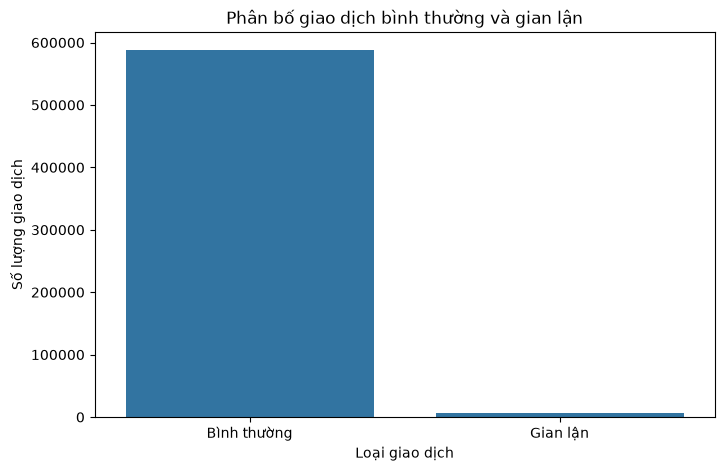

In [192]:
import matplotlib.pyplot as plt
import seaborn as sns

# Đếm số lượng giao dịch
fraud_counts = df["fraud"].value_counts().sort_index()

# Vẽ biểu đồ
plt.figure(figsize=(8, 5))

sns.barplot(
    x=fraud_counts.index,
    y=fraud_counts.values
)

plt.title("Phân bố giao dịch bình thường và gian lận")
plt.xlabel("Loại giao dịch")
plt.ylabel("Số lượng giao dịch")

plt.xticks([0, 1], ["Bình thường", "Gian lận"])

plt.show()

In [164]:
# Thống kê số tiền theo nhãn fraud
amount_stats = df.groupby("fraud")["amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(amount_stats)

        count        mean   median         std   min      max
fraud                                                        
0      587443   31.847230   26.610   31.470876  0.00  2144.86
1        7200  530.926551  319.175  835.587112  0.03  8329.96


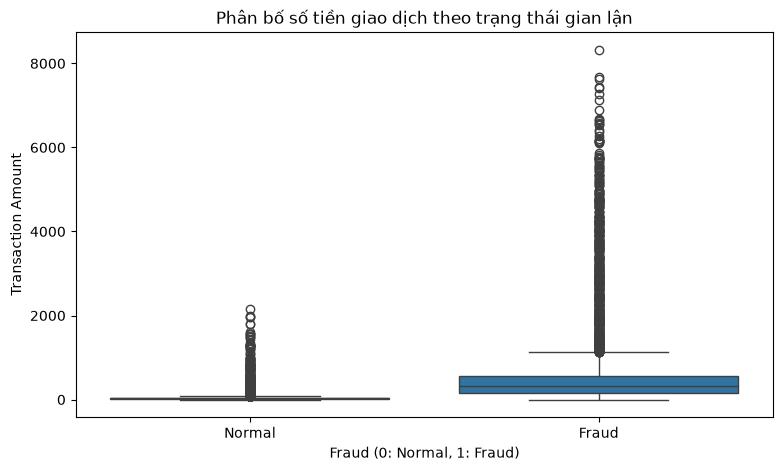

In [165]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="fraud",
    y="amount"
)

plt.title("Phân bố số tiền giao dịch theo trạng thái gian lận")
plt.xlabel("Fraud (0: Normal, 1: Fraud)")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Normal", "Fraud"])

plt.show()

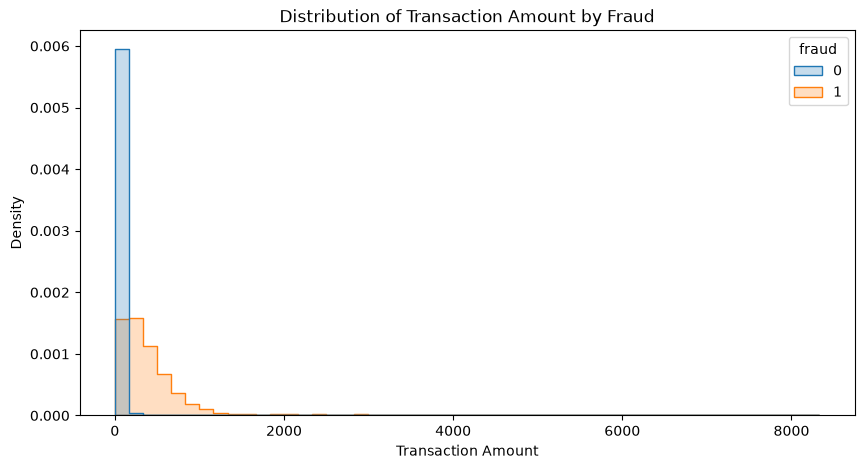

In [166]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="amount",
    hue="fraud",
    bins=50,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Distribution of Transaction Amount by Fraud")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.show()

In [167]:
# Đếm số lượng giao dịch theo từng category
category_counts = df["category"].value_counts()

print("Số lượng giao dịch theo category:")
print(category_counts)

Số lượng giao dịch theo category:
category
es_transportation        505119
es_food                   26254
es_health                 16133
es_wellnessandbeauty      15086
es_fashion                 6454
es_barsandrestaurants      6373
es_hyper                   6098
es_sportsandtoys           4002
es_tech                    2370
es_home                    1986
es_hotelservices           1744
es_otherservices            912
es_contents                 885
es_travel                   728
es_leisure                  499
Name: count, dtype: int64


In [168]:
# Thống kê giao dịch theo category
category_stats = df.groupby("category").agg(
    total_transactions=("fraud", "count"),
    fraud_transactions=("fraud", "sum")
)

# Tính số giao dịch bình thường
category_stats["normal_transactions"] = (
    category_stats["total_transactions"]
    - category_stats["fraud_transactions"]
)

# Tính tỷ lệ gian lận trong từng category
category_stats["fraud_rate"] = (
    category_stats["fraud_transactions"]
    / category_stats["total_transactions"]
    * 100
)

# Sắp xếp theo tỷ lệ gian lận giảm dần
category_stats = category_stats.sort_values(
    by="fraud_rate",
    ascending=False
)

print(category_stats)

                       total_transactions  fraud_transactions  \
category                                                        
es_leisure                            499                 474   
es_travel                             728                 578   
es_sportsandtoys                     4002                1982   
es_hotelservices                     1744                 548   
es_otherservices                      912                 228   
es_home                              1986                 302   
es_health                           16133                1696   
es_tech                              2370                 158   
es_wellnessandbeauty                15086                 718   
es_hyper                             6098                 280   
es_barsandrestaurants                6373                 120   
es_fashion                           6454                 116   
es_contents                           885                   0   
es_food                  

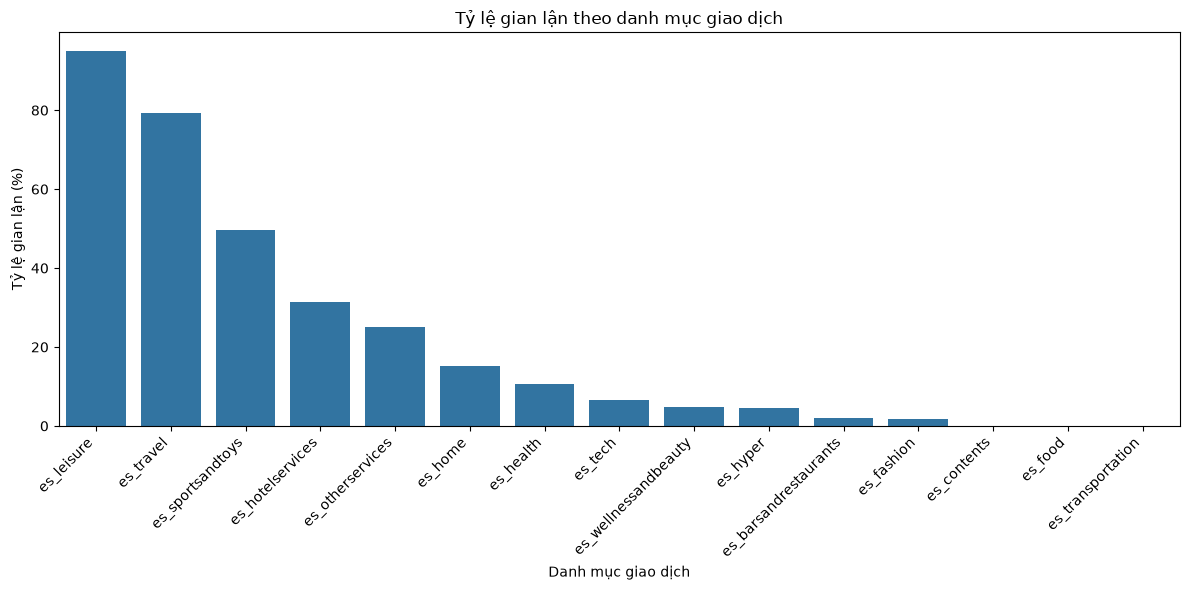

In [169]:
# TRỰC QUAN HÓA: TỶ LỆ GIAN LẬN THEO DANH MỤC GIAO DỊCH

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_stats,
    x=category_stats.index,
    y="fraud_rate"
)

plt.title("Tỷ lệ gian lận theo danh mục giao dịch")
plt.xlabel("Danh mục giao dịch")
plt.ylabel("Tỷ lệ gian lận (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

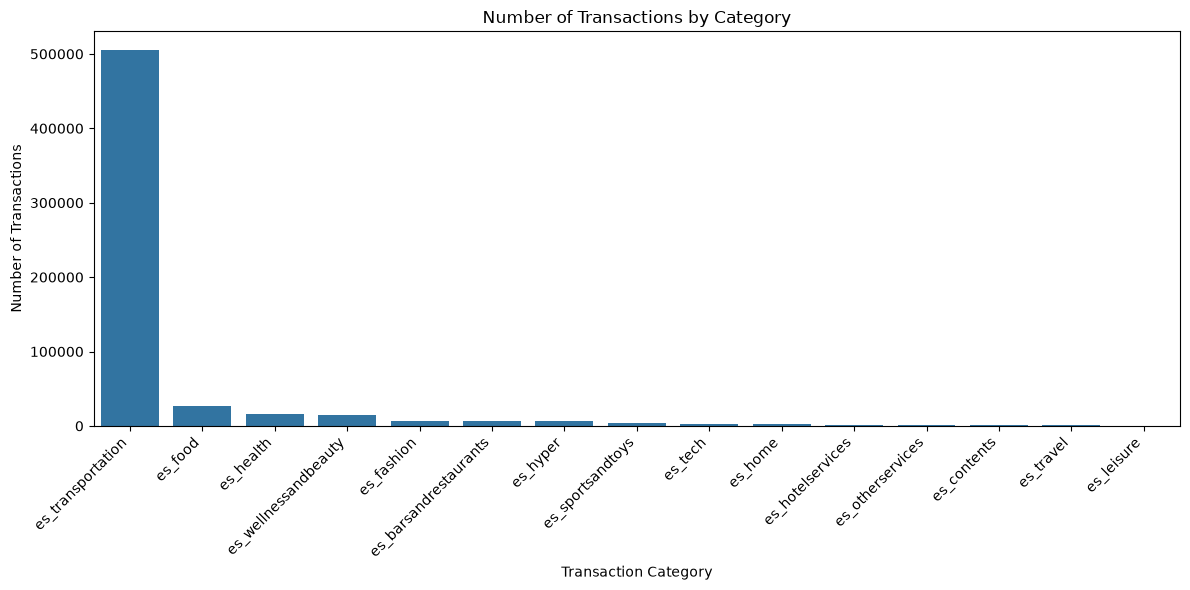

In [170]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="category",
    order=df["category"].value_counts().index
)

plt.title("Number of Transactions by Category")
plt.xlabel("Transaction Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [171]:
# ANALYSIS: FRAUD DISTRIBUTION BY AGE AND GENDER

# 1. Transaction distribution by age
age_stats = df.groupby("age").agg(
    total_transactions=("fraud", "count"),
    fraud_transactions=("fraud", "sum")
)

age_stats["fraud_rate"] = (
    age_stats["fraud_transactions"]
    / age_stats["total_transactions"] * 100
)

print("Fraud statistics by age:")
display(age_stats)

# 2. Transaction distribution by gender
gender_stats = df.groupby("gender").agg(
    total_transactions=("fraud", "count"),
    fraud_transactions=("fraud", "sum")
)

gender_stats["fraud_rate"] = (
    gender_stats["fraud_transactions"]
    / gender_stats["total_transactions"] * 100
)

print("Fraud statistics by gender:")
display(gender_stats)

Fraud statistics by age:


,total_transactions,fraud_transactions,fraud_rate
age,,,
0,2452,48,1.957586
1,58131,689,1.185254
2,187310,2344,1.251401
3,147131,1755,1.192815
4,109025,1410,1.293281
5,62642,686,1.095112
6,26774,261,0.974826
U,1178,7,0.594228


Fraud statistics by gender:


,total_transactions,fraud_transactions,fraud_rate
gender,,,
E,1178,7,0.594228
F,324565,4758,1.465962
M,268385,2435,0.907279
U,515,0,0.000000


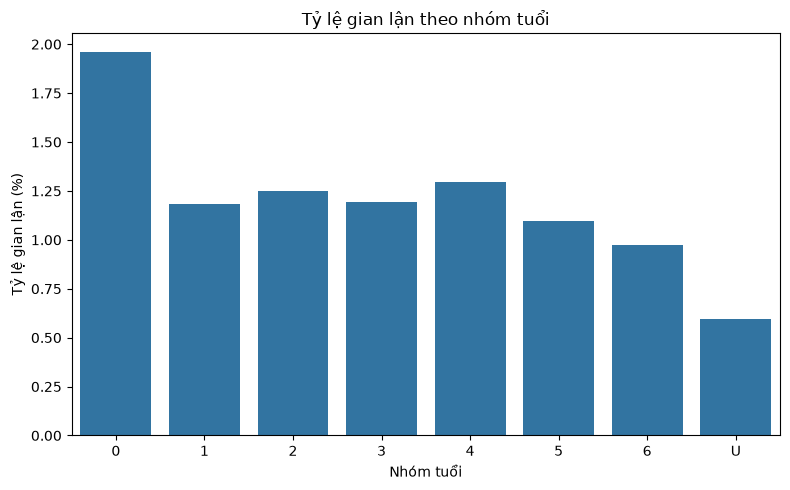

In [172]:
# TRỰC QUAN HÓA: TỶ LỆ GIAN LẬN THEO NHÓM TUỔI

plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_stats.reset_index(),
    x="age",
    y="fraud_rate"
)

plt.title("Tỷ lệ gian lận theo nhóm tuổi")
plt.xlabel("Nhóm tuổi")
plt.ylabel("Tỷ lệ gian lận (%)")

plt.tight_layout()
plt.savefig("../results/figures/fraud_rate_by_age.png", dpi=300)
plt.show()

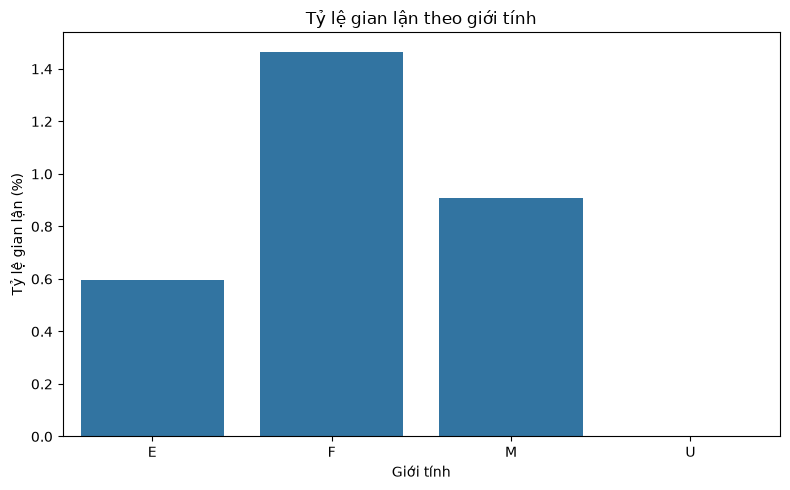

In [173]:
# TRỰC QUAN HÓA: TỶ LỆ GIAN LẬN THEO GIỚI TÍNH

plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_stats.reset_index(),
    x="gender",
    y="fraud_rate"
)

plt.title("Tỷ lệ gian lận theo giới tính")
plt.xlabel("Giới tính")
plt.ylabel("Tỷ lệ gian lận (%)")

plt.tight_layout()
plt.savefig("../results/figures/fraud_rate_by_gender.png", dpi=300)
plt.show()

In [174]:
# ANALYSIS: ZIPCODE ATTRIBUTES

zipcode_stats = pd.DataFrame({
    "Column": ["zipcodeOri", "zipMerchant"],
    "Unique Values": [
        df["zipcodeOri"].nunique(),
        df["zipMerchant"].nunique()
    ],
    "Missing Values": [
        df["zipcodeOri"].isnull().sum(),
        df["zipMerchant"].isnull().sum()
    ]
})

print("Zipcode attribute analysis:")
display(zipcode_stats)

print("\nUnique values of zipcodeOri:")
print(df["zipcodeOri"].unique())

print("\nUnique values of zipMerchant:")
print(df["zipMerchant"].unique())

Zipcode attribute analysis:


,Column,Unique Values,Missing Values
0,zipcodeOri,1,0
1,zipMerchant,1,0



Unique values of zipcodeOri:
[28007]

Unique values of zipMerchant:
[28007]


In [175]:
# Đếm số lượng khách hàng khác nhau
unique_customers = df["customer"].nunique()

print("Tổng số khách hàng:", unique_customers)

Tổng số khách hàng: 4112


In [176]:
# Đếm số giao dịch của từng khách hàng
customer_counts = df["customer"].value_counts()

print("10 khách hàng có nhiều giao dịch nhất:")
print(customer_counts.head(10))

10 khách hàng có nhiều giao dịch nhất:
customer
C1978250683    265
C1275518867    252
C806399525     237
C515668508     205
C1338396147    195
C1896850232    192
C1350963410    191
C980876590     189
C582688427     188
C1090528803    188
Name: count, dtype: int64


In [177]:
# Thống kê số giao dịch của mỗi khách hàng
customer_transaction_stats = customer_counts.describe()

print("Thống kê số giao dịch trên mỗi khách hàng:")
print(customer_transaction_stats)

Thống kê số giao dịch trên mỗi khách hàng:
count    4112.000000
mean      144.611625
std        42.788212
min         5.000000
25%       130.000000
50%       165.000000
75%       173.000000
max       265.000000
Name: count, dtype: float64


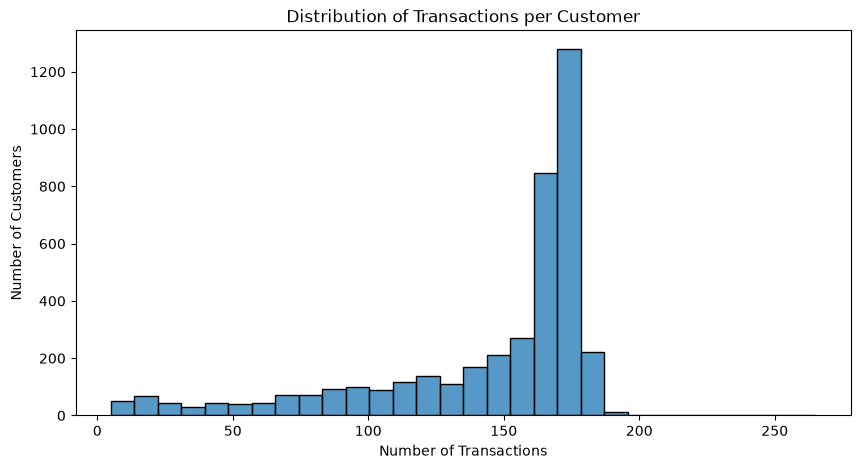

In [178]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    customer_counts,
    bins=30
)

plt.title("Distribution of Transactions per Customer")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")

plt.show()

In [179]:
# Tổng hợp giao dịch theo từng khách hàng
customer_fraud_stats = df.groupby("customer").agg(
    total_transactions=("fraud", "count"),
    fraud_transactions=("fraud", "sum"),
    total_amount=("amount", "sum"),
    average_amount=("amount", "mean")
)

# Tính số giao dịch bình thường
customer_fraud_stats["normal_transactions"] = (
    customer_fraud_stats["total_transactions"]
    - customer_fraud_stats["fraud_transactions"]
)

# Tính tỷ lệ gian lận theo khách hàng
customer_fraud_stats["fraud_rate"] = (
    customer_fraud_stats["fraud_transactions"]
    / customer_fraud_stats["total_transactions"]
    * 100
)

print("Thông tin hành vi khách hàng:")
print(customer_fraud_stats.head())

Thông tin hành vi khách hàng:
             total_transactions  fraud_transactions  total_amount  \
customer                                                            
C1000148617                 131                   1       4597.04   
C100045114                  109                   5       9846.65   
C1000699316                  94                   0       3586.56   
C1001065306                  30                  11       6142.64   
C1002658784                 131                   0       4487.18   

             average_amount  normal_transactions  fraud_rate  
customer                                                      
C1000148617       35.091908                  130    0.763359  
C100045114        90.336239                  104    4.587156  
C1000699316       38.154894                   94    0.000000  
C1001065306      204.754667                   19   36.666667  
C1002658784       34.253282                  131    0.000000  


In [180]:
# Sắp xếp theo số giao dịch gian lận giảm dần
top_fraud_customers = customer_fraud_stats.sort_values(
    by="fraud_transactions",
    ascending=False
)

print("10 khách hàng có nhiều giao dịch gian lận nhất:")
print(top_fraud_customers.head(10))

10 khách hàng có nhiều giao dịch gian lận nhất:
             total_transactions  fraud_transactions  total_amount  \
customer                                                            
C1350963410                 191                 144      56217.36   
C1849046345                 171                 127      60693.04   
C806399525                  237                 125      83755.49   
C2004941826                 126                 119      64751.08   
C1275518867                 252                 114      52964.37   
C1978250683                 265                 110      55965.05   
C381007057                  100                  89      51388.87   
C1572610482                 101                  89      58687.13   
C1817318774                 112                  87      46100.12   
C910454738                   92                  87      37795.51   

             average_amount  normal_transactions  fraud_rate  
customer                                                    

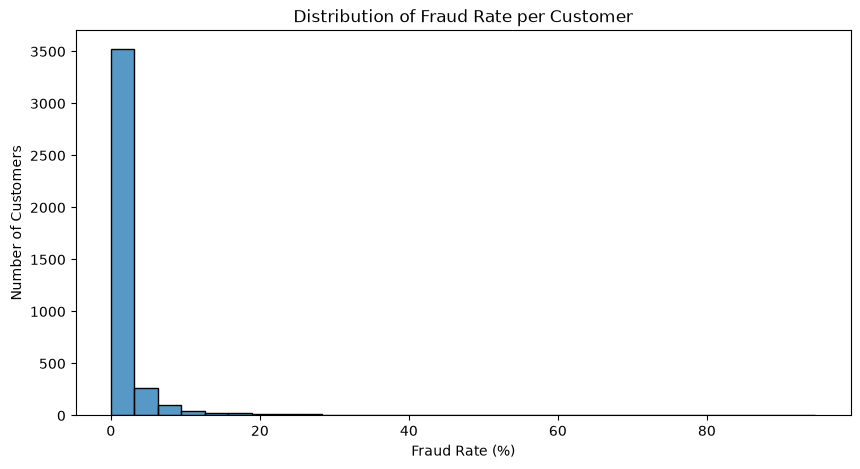

In [181]:
# Lọc các khách hàng có ít nhất 10 giao dịch
customer_plot = customer_fraud_stats[
    customer_fraud_stats["total_transactions"] >= 10
]

plt.figure(figsize=(10, 5))

sns.histplot(
    data=customer_plot,
    x="fraud_rate",
    bins=30
)

plt.title("Distribution of Fraud Rate per Customer")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Number of Customers")

plt.show()

In [182]:
# Đếm số merchant khác nhau
unique_merchants = df["merchant"].nunique()

print("Tổng số merchant:", unique_merchants)

Tổng số merchant: 50


In [183]:
# Đếm số giao dịch của từng merchant
merchant_counts = df["merchant"].value_counts()

print("10 merchant có nhiều giao dịch nhất:")
print(merchant_counts.head(10))

10 merchant có nhiều giao dịch nhất:
merchant
M1823072687    299693
M348934600     205426
M85975013       26254
M1053599405      6821
M151143676       6373
M855959430       6098
M1946091778      5343
M1913465890      3988
M209847108       3814
M480139044       3508
Name: count, dtype: int64


In [184]:
# Tổng hợp giao dịch theo merchant
merchant_fraud_stats = df.groupby("merchant").agg(
    total_transactions=("fraud", "count"),
    fraud_transactions=("fraud", "sum"),
    total_amount=("amount", "sum"),
    average_amount=("amount", "mean")
)

# Tính số giao dịch bình thường
merchant_fraud_stats["normal_transactions"] = (
    merchant_fraud_stats["total_transactions"]
    - merchant_fraud_stats["fraud_transactions"]
)

# Tính tỷ lệ gian lận
merchant_fraud_stats["fraud_rate"] = (
    merchant_fraud_stats["fraud_transactions"]
    / merchant_fraud_stats["total_transactions"]
    * 100
)

print("Thống kê gian lận theo merchant:")
print(merchant_fraud_stats.head())

Thống kê gian lận theo merchant:
             total_transactions  fraud_transactions  total_amount  \
merchant                                                            
M1053599405                6821                   0     703056.31   
M117188757                   21                   0       2207.15   
M1198415165                1580                 358     149504.20   
M1294758098                 191                 184      55326.42   
M1313686961                 527                   0      23500.82   

             average_amount  normal_transactions  fraud_rate  
merchant                                                      
M1053599405      103.072322                 6821    0.000000  
M117188757       105.102381                   21    0.000000  
M1198415165       94.622911                 1222   22.658228  
M1294758098      289.667120                    7   96.335079  
M1313686961       44.593586                  527    0.000000  


In [185]:
top_fraud_merchants = merchant_fraud_stats.sort_values(
    by="fraud_transactions",
    ascending=False
)

print("10 merchant có nhiều giao dịch gian lận nhất:")
print(top_fraud_merchants.head(10).to_string())

10 merchant có nhiều giao dịch gian lận nhất:
             total_transactions  fraud_transactions  total_amount  average_amount  normal_transactions  fraud_rate
merchant                                                                                                          
M480139044                 3508                1634     858388.22      244.694475                 1874   46.579247
M980657600                 1769                1472     530635.69      299.963646                  297   83.210854
M732195782                  608                 518    1413661.65     2325.101398                   90   85.197368
M1198415165                1580                 358     149504.20       94.622911                 1222   22.658228
M3697346                    308                 290      88840.32      288.442597                   18   94.155844
M855959430                 6098                 280     280327.63       45.970421                 5818    4.591669
M1888755466                 912   

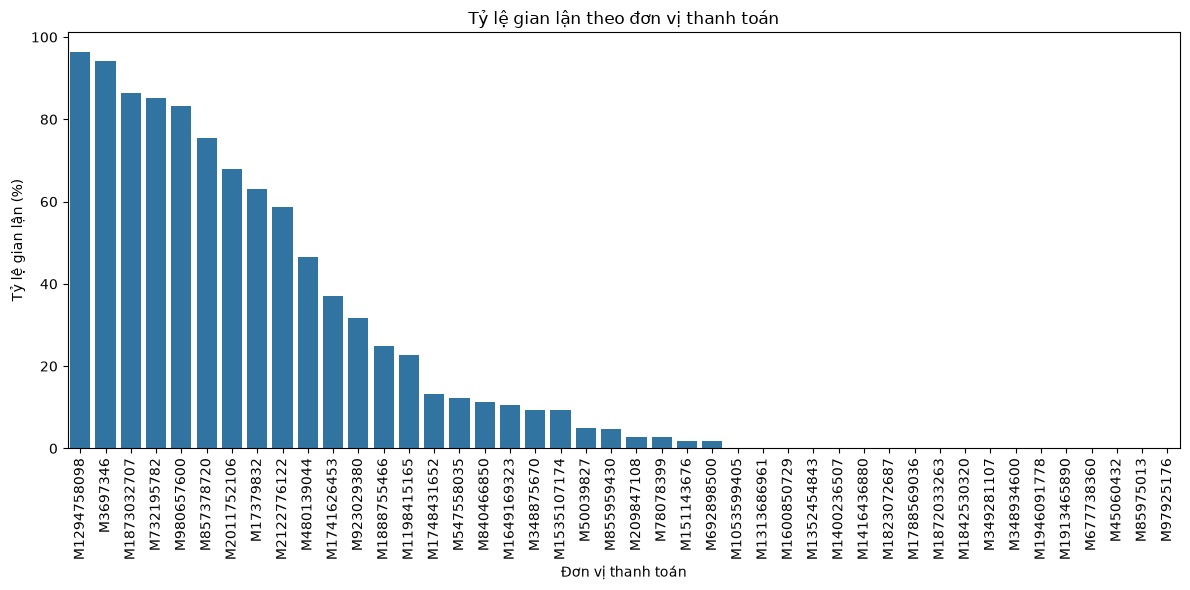

In [186]:
# TRỰC QUAN HÓA: TỶ LỆ GIAN LẬN THEO ĐƠN VỊ THANH TOÁN

# Chỉ lấy merchant có ít nhất 100 giao dịch
merchant_plot = merchant_fraud_stats[
    merchant_fraud_stats["total_transactions"] >= 100
].sort_values(
    by="fraud_rate",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=merchant_plot.index,
    y=merchant_plot["fraud_rate"]
)

plt.title("Tỷ lệ gian lận theo đơn vị thanh toán")
plt.xlabel("Đơn vị thanh toán")
plt.ylabel("Tỷ lệ gian lận (%)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [187]:
# Thống kê số lượng giao dịch theo step
step_counts = df["step"].value_counts().sort_index()

print("Số lượng giao dịch theo step:")
print(step_counts.describe())

print("\n10 step đầu tiên:")
print(step_counts.head(10))

print("\n10 step cuối cùng:")
print(step_counts.tail(10))

Số lượng giao dịch theo step:
count     180.000000
mean     3303.572222
std       361.659799
min      2424.000000
25%      3057.250000
50%      3393.500000
75%      3607.250000
max      3774.000000
Name: count, dtype: float64

10 step đầu tiên:
step
0    2430
1    2424
2    2462
3    2499
4    2532
5    2525
6    2580
7    2539
8    2575
9    2638
Name: count, dtype: int64

10 step cuối cùng:
step
170    3715
171    3716
172    3728
173    3739
174    3743
175    3774
176    3721
177    3758
178    3743
179    3709
Name: count, dtype: int64


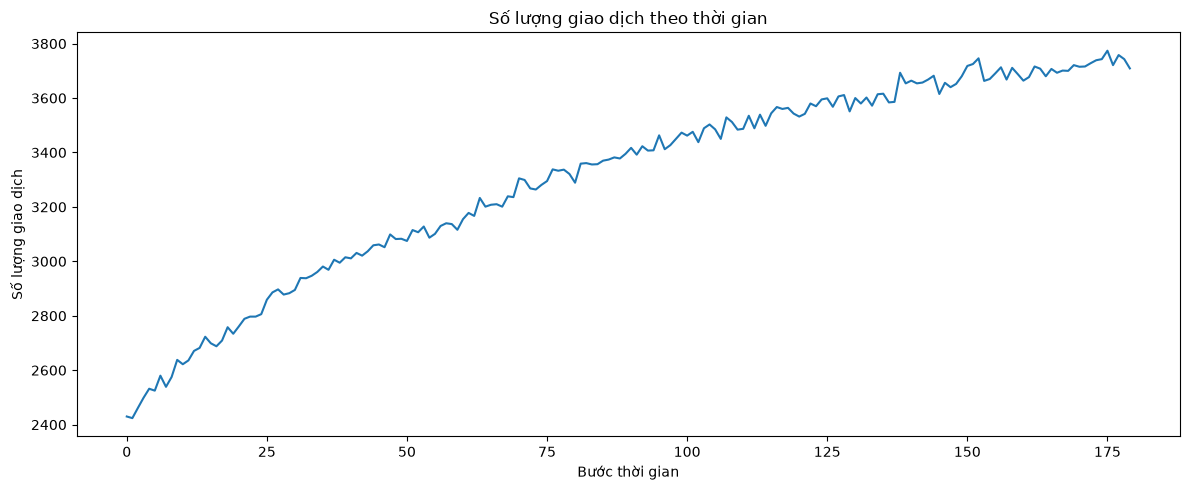

In [188]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=step_counts.index,
    y=step_counts.values
)

plt.title("Số lượng giao dịch theo thời gian")
plt.xlabel("Bước thời gian")
plt.ylabel("Số lượng giao dịch")

plt.tight_layout()
plt.show()

In [189]:
# Tổng hợp giao dịch theo step
step_fraud_stats = df.groupby("step").agg(
    total_transactions=("fraud", "count"),
    fraud_transactions=("fraud", "sum")
)

# Tính số giao dịch bình thường
step_fraud_stats["normal_transactions"] = (
    step_fraud_stats["total_transactions"]
    - step_fraud_stats["fraud_transactions"]
)

# Tính tỷ lệ gian lận
step_fraud_stats["fraud_rate"] = (
    step_fraud_stats["fraud_transactions"]
    / step_fraud_stats["total_transactions"]
    * 100
)

print(step_fraud_stats.head(10))

      total_transactions  fraud_transactions  normal_transactions  fraud_rate
step                                                                         
0                   2430                  40                 2390    1.646091
1                   2424                  40                 2384    1.650165
2                   2462                  40                 2422    1.624695
3                   2499                  40                 2459    1.600640
4                   2532                  40                 2492    1.579779
5                   2525                  40                 2485    1.584158
6                   2580                  40                 2540    1.550388
7                   2539                  40                 2499    1.575423
8                   2575                  40                 2535    1.553398
9                   2638                  40                 2598    1.516300


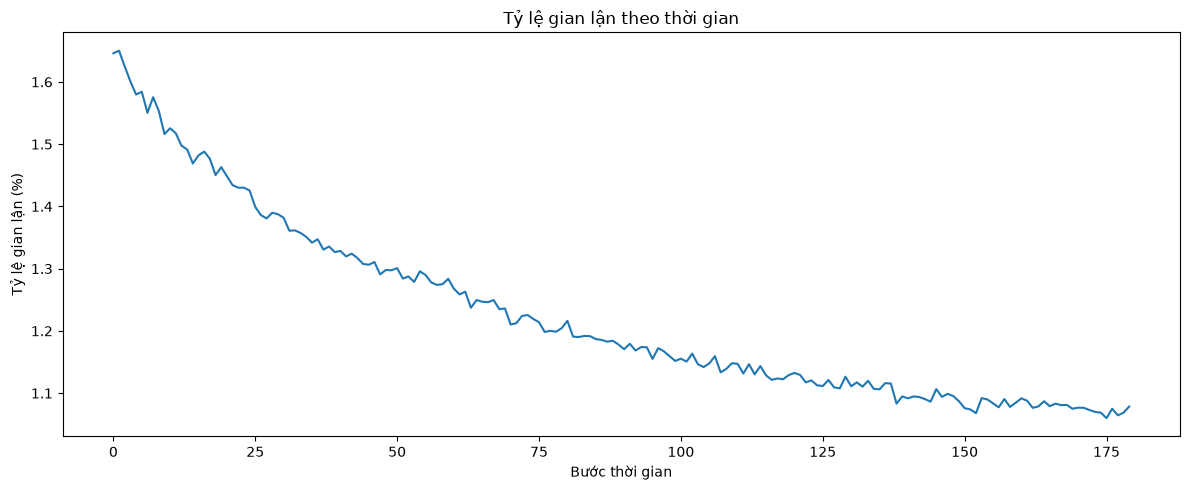

In [190]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=step_fraud_stats,
    x=step_fraud_stats.index,
    y="fraud_rate"
)

plt.title("Tỷ lệ gian lận theo thời gian")
plt.xlabel("Bước thời gian")
plt.ylabel("Tỷ lệ gian lận (%)")

plt.tight_layout()
plt.show()

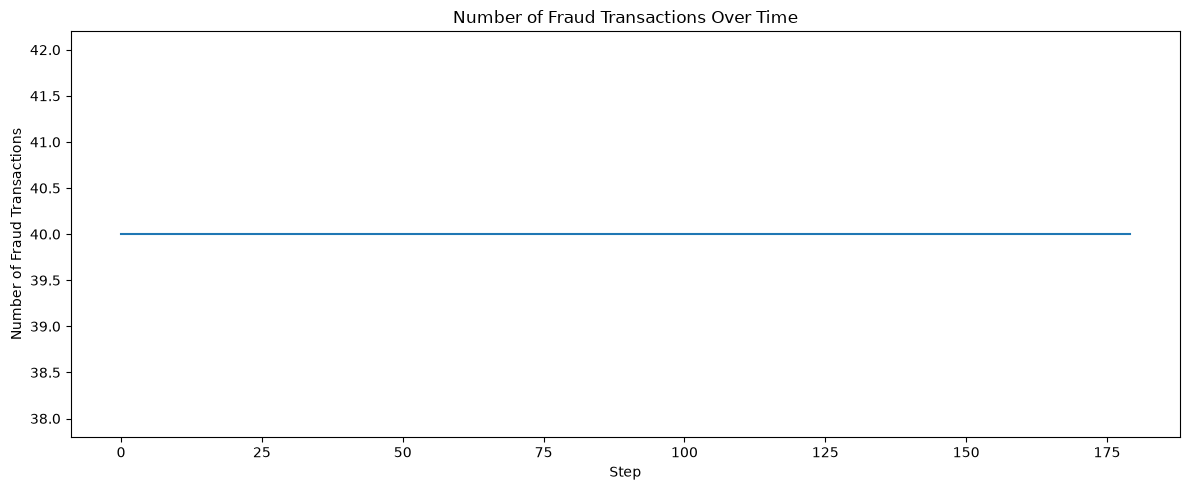

In [191]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=step_fraud_stats,
    x=step_fraud_stats.index,
    y="fraud_transactions"
)

plt.title("Number of Fraud Transactions Over Time")
plt.xlabel("Step")
plt.ylabel("Number of Fraud Transactions")

plt.tight_layout()
plt.show()